In [13]:
import sys
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [14]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [5]:
# file_ids = list(range(0, 8+1))
file_ids = [2]
plot_id = 2

In [6]:
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')

# read
(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_datas(path, file_ids, with_whisking=True)

# clear nan values
for i in range(len(file_ids)):
	# mask = motion_pcs[i][0].notna().all(axis=1)
	mask = continuous_behaviors[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	motion_pcs[i][0] = motion_pcs[i][0][mask]
	motion_pcs[i][1] = motion_pcs[i][1][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# preprocess
def reconstruct_calcium(spikes, fs, decay=2.0):
	dt = 1.0 / fs
	gamma = np.exp(-dt / decay)
	trace = np.zeros(spikes.shape, dtype=np.float32)
	for t in range(1, spikes.shape[0]):
		trace[t, :] = gamma * trace[t - 1, :] + spikes[t, :]
	return trace

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]
traces = [pd.DataFrame(reconstruct_calcium(trace.values, fs=sr), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]
classes = [pd.DataFrame(
	cb[['running_speed']].values > np.quantile(cb[['running_speed']].values, 0.05),
	columns=['run']
) for cb in continuous_behaviors]

In [7]:
plot_idx = file_ids.index(plot_id)

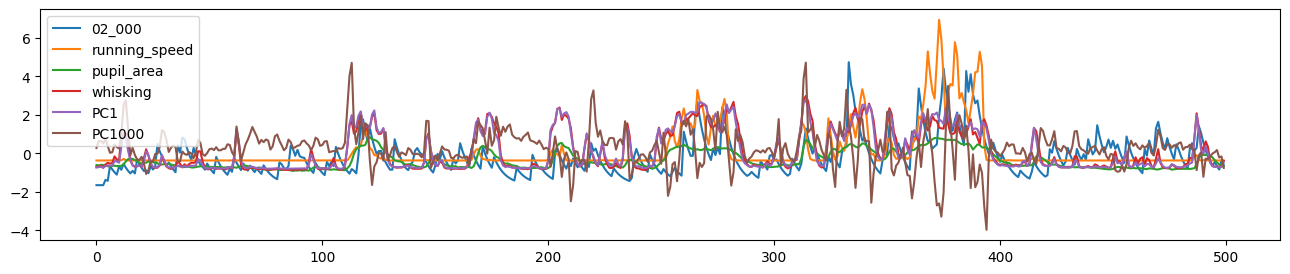

In [10]:
plt.figure(figsize=(16, 3))
DATA = [
		traces[plot_idx].iloc[:, 0:1],
		continuous_behaviors[plot_idx][['running_speed']],
		continuous_behaviors[plot_idx][['pupil_area']],
		continuous_behaviors[plot_idx][['whisking']],
		motion_pcs[plot_idx][0][['PC1']] * -1,
		motion_pcs[plot_idx][0][['PC1000']],
]

for data in DATA:
	data -= data.mean(axis=0)
	data /= np.where((data_std := np.std(data, axis=0)) == 0.0, 1.0, data_std)
	plt.plot(data.values[:500], label=data.columns[0])
plt.legend()

In [15]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, scale=False,
												 n_pc=1)

In [24]:
df = pd.concat([
	pd.DataFrame(modes_manifold[0]['PC1'].values, columns=['NPC1']),
    continuous_behaviors[plot_idx][['running_speed']],
    continuous_behaviors[plot_idx][['pupil_area']],
    continuous_behaviors[plot_idx][['whisking']],
    motion_pcs[plot_idx][0][['PC1']] * -1,
    motion_pcs[plot_idx][0][['PC2']] * -1,
    motion_pcs[plot_idx][0][['PC3']] * -1,
], axis=1)
print(df.corr())

                   NPC1  running_speed  pupil_area  whisking       PC1  \
NPC1           1.000000       0.297451    0.207985  0.278633  0.302084   
running_speed  0.297451       1.000000    0.417250  0.597839  0.639954   
pupil_area     0.207985       0.417250    1.000000  0.473692  0.475813   
whisking       0.278633       0.597839    0.473692  1.000000  0.981866   
PC1            0.302084       0.639954    0.475813  0.981866  1.000000   
PC2            0.179727       0.260109    0.159697  0.073497  0.208129   
PC3           -0.131319      -0.335771   -0.165682 -0.005637 -0.010479   

                    PC2       PC3  
NPC1           0.179727 -0.131319  
running_speed  0.260109 -0.335771  
pupil_area     0.159697 -0.165682  
whisking       0.073497 -0.005637  
PC1            0.208129 -0.010479  
PC2            1.000000 -0.270212  
PC3           -0.270212  1.000000  
